# Práctica: _Quantum Phase Estimation_

A lo largo de esta notebook, se implementará el código necesario para la resolución del práctico. En esta no se hallan conclusiones detalladas, pues estas se encuentran en el informe y duplicarlas acá haría más difícil la mantenibilidad en caso de que alguno de los artefactos (el informe o el código) se modificase.

![](images/qpe.png)

## Importación de Bibliotecas

In [15]:
import io
import math
import numpy as np
from math import pi
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import display, Image

from qiskit.circuit import Gate
from qiskit_aer import AerSimulator
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import ZGate, SGate, TGate, RZGate

from collections import Counter, defaultdict

## Ejercicio 1

### Consigna

Implemente el QPE visto en el curso considerando diferentes operadores unitarios de rotación $U$ y diferentes cantidades de qubits objetivo ($m$) y qubits de estimación ($t$):

i. $U = Z$; $U = S$; $U = T$; $U = Rz(𝝅)$; $U = Rz(𝝅/2)$; $U = Rz(𝝅/4)$; $U = Rz(3𝝅/4)$; ($m = 1$ y $t = 4$).

ii. inciso i) con m = 2

iii. inciso i) con t = 6

iv. U = Rz(-𝝅/4); U = Rz(-3𝝅/4); (m = 1 y t = 4)

### Resolución

#### Transformada Inversa de Fourier

Como paso previo a la implementación del algoritmo QPE, se requiere implementar la transformada inversa cuántica de Fourier ($QFT^{-1}$).

Dicha implementación puede extraerse de las resoluciones de los prácticos anteriores.

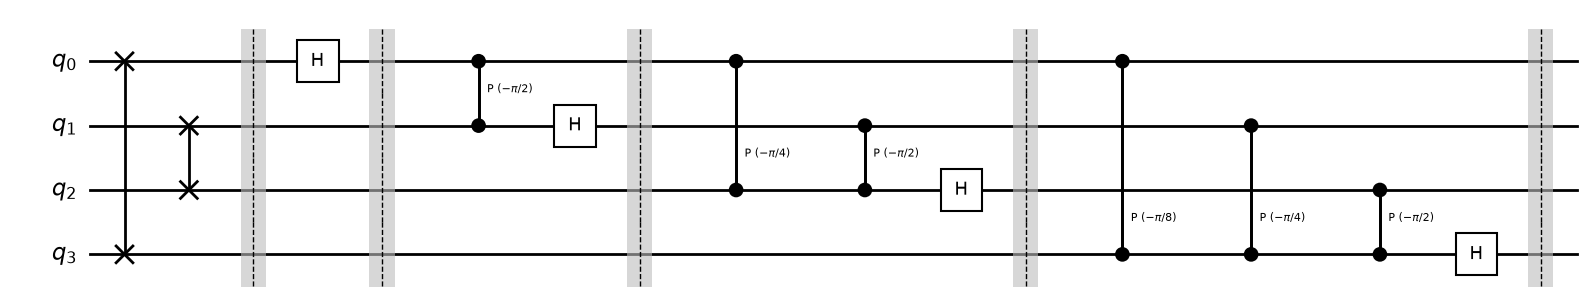

In [16]:
def iqtf(number_of_qubits):
    
    quantum_circuit = QuantumCircuit(number_of_qubits, name="IQTF")
    
    accessible_qubits = number_of_qubits - 1
    
    # Swap entre el qubit 0 y el n - 1.
    # Swap entre el qubit 1 y el n - 2.
    # Y así hasta llegar al centro.
    
    # Los swaps pueden ahorrarse si se invierte el orden de los qubits resultados.
    for i in range(int(number_of_qubits/2)):
        quantum_circuit.swap(i, accessible_qubits - i)
        
    quantum_circuit.barrier()
        
    # Por cada qubit, se aplica una rotación extra.
    # Al primer qubit, solo se le aplica Hadamard.
    # Al segundo, una rotación de pi/2 y Hadamard.
    # Al tercero, una rotación de pi/4, una rotación de pi/2 y Hadamard.
    for i in range(number_of_qubits):
        
        for j in range(i, 0, -1):
            # cp(ángulo, control, objetivo)
            quantum_circuit.cp(-pi/(2 ** j), i - j, i)
        
        # Se aplica un Hadamard luego de las rotaciones.
        quantum_circuit.h(i)
        
        # Se aplica una barrera para evitar el autoordenamiento de Qiskit.
        quantum_circuit.barrier()
        
    return quantum_circuit
        
qc = iqtf(4)
qc.draw(output='mpl', style='bw')

#### QPE

A continuación, se define una función que, dado un número de qubits objetivos ($m$), un número de qubits de estimación ($t$) y un operador unitario, devuelve la implementación del QPE correspondiente.

In [17]:
def qpe(qubits_objetivo: int, qubits_estimacion: int, operador_unitario: Gate) -> QuantumCircuit:
    
    qubits_totales: int = qubits_objetivo + qubits_estimacion
    
    quantum_circuit = QuantumCircuit(qubits_totales, name="QPE")
    
    # Se le aplica Hadamard a cada qubit de estimación.
    for i in range(qubits_estimacion):
        quantum_circuit.h(i)
    
    # Operadores unitarios controlados.
    for i in range(qubits_estimacion):
        controlled_u = (operador_unitario ** (2 ** i)).control(1)

        for j in range(qubits_estimacion, qubits_totales):
            quantum_circuit.append(controlled_u, [i, j])
            
    # Aplicación de la transformada cuántica inversa de Fourier.
    quantum_circuit.append(iqtf(qubits_estimacion), range(0, qubits_estimacion))
    
    return quantum_circuit

##### Inciso i)

$m = 1$ y $t = 4$

In [18]:
m = 1
t = 4

Se define una función para obtener los distintos operadores unitarios de rotación $U$ descritos en el enunciado:

In [19]:
def get_unitary_rotation_operator(operator: str) -> Gate:
    operators = {
        "Z": ZGate(),
        "S": SGate(),
        "T": TGate(),
        "Rz(π)": RZGate(pi),
        "Rz(π/2)": RZGate(pi / 2),
        "Rz(π/4)": RZGate(pi / 4),
        "Rz(3π/4)": RZGate(3 * pi / 4),
        "Rz(-π/4)": RZGate(-pi / 4),
        "Rz(-3π/4)": RZGate(-3 * pi / 4),
    }

    if operator not in operators:
        raise ValueError(f"Unsupported operator: {operator}")

    return operators[operator]

Se visualiza el circuito para cada uno de los operadores unitarios descritos en el inciso:

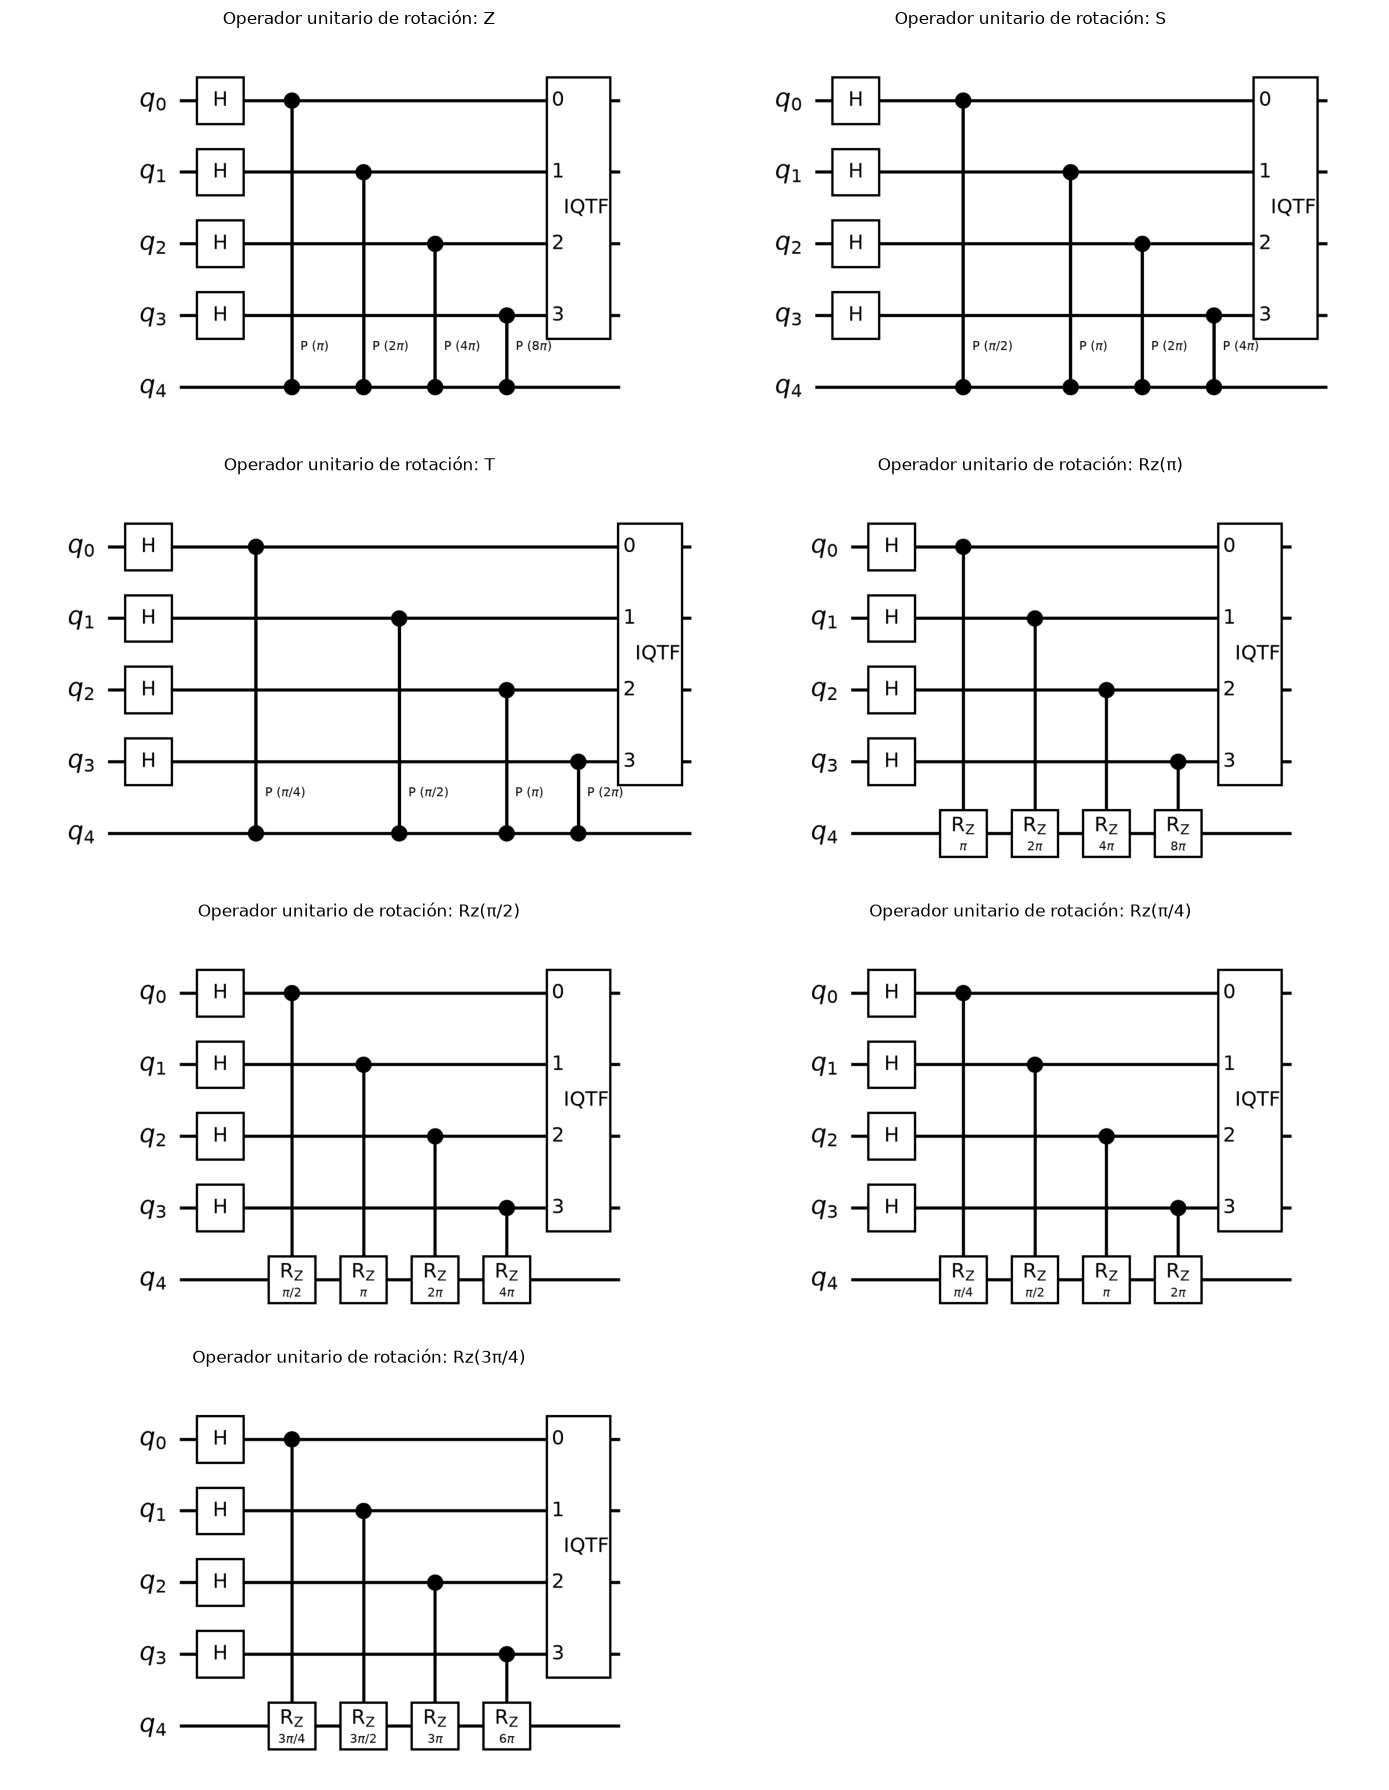

In [20]:
unitary_rotation_operators = ["Z", "S", "T", "Rz(π)", "Rz(π/2)", "Rz(π/4)", "Rz(3π/4)"]


def circuit_to_array(qc: QuantumCircuit, dpi: int = 200):
    # Se dibuja el circuito y se lo convierte en imagen para poder ubicarlo en una grilla.
    fig = qc.draw(output="mpl", style="bw")

    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=dpi, bbox_inches="tight")
    plt.close(fig)

    buffer.seek(0)
    return mpimg.imread(buffer)


def plot_circuits_grid(operators: list, m: int, t: int, columns: int = 3):
    rows = math.ceil(len(operators) / columns)

    fig, axes = plt.subplots(rows, columns, figsize=(7 * columns, 4.5 * rows), squeeze=False)
    axes = axes.flatten()

    for ax, operator in zip(axes, operators):
        qc = qpe(m, t, get_unitary_rotation_operator(operator))

        ax.imshow(circuit_to_array(qc))
        ax.set_title(f"Operador unitario de rotación: {operator}", fontsize=12)
        ax.axis("off")

    # Se ocultan los ejes sobrantes de la última fila.
    for ax in axes[len(operators):]:
        ax.axis("off")

    fig.tight_layout()
    plt.show()


plot_circuits_grid(unitary_rotation_operators, m, t, columns=2)

A continuación, se define un conjunto de funciones auxiliares que permite realizar la ejecución de los circuitos.

In [21]:
def simulate(qc: QuantumCircuit, shots: int = 1024):
    measured_qc = qc.copy()
    measured_qc.measure_all()

    simulator = AerSimulator()
    compiled_qc = transpile(measured_qc, simulator)

    result = simulator.run(compiled_qc, shots=shots).result()

    return result.get_counts()

def build_evaluation_circuit(m: int, t: int, operator: Gate) -> QuantumCircuit:
    # Se obtiene el circuito QPE para dicho operador.
    qpe_qc = qpe(m, t, operator)

    # Se preparan los qubits objetivo en superposición. Al ser todos
    # autoestados de los operadores diagonales, se evalúan todos a la vez.
    qc = QuantumCircuit(m + t)
    qc.h(range(t, t + m))

    # Se añade el QPE luego de las superposiciones.
    qc.compose(qpe_qc, inplace=True)

    return qc


def group_by_target_state(counts: dict, m: int) -> dict:
    # Se agrupan los resultados por estado objetivo.
    grouped = defaultdict(Counter)

    for measured, occurrences in counts.items():
        bits = measured.replace(" ", "")

        target_state = bits[:m][::-1]
        estimation_bits = bits[m:]

        grouped[target_state][estimation_bits] += occurrences

    return grouped


def expected_phase_of(diagonal: np.ndarray, target_state: str) -> float:
    # Fase teórica: suma de las fases de cada qubit.
    return sum(
        np.angle(diagonal[int(bit)]) / (2 * np.pi)
        for bit in target_state
    ) % 1


def circular_error(measured_phase: float, expected_phase: float) -> float:
    # Error circular entre fases.
    return abs((measured_phase - expected_phase + 0.5) % 1 - 0.5)



def evaluate_operator(operator_name: str, m: int, t: int, shots: int) -> list:
    rows = []

    # Se obtiene el operador unitario.
    operator = get_unitary_rotation_operator(operator_name)
    # Se diagonaliza el operador.
    diagonal = np.diag(operator.to_matrix())

    qc = build_evaluation_circuit(m, t, operator)

    # Se realiza la simulación.
    counts = simulate(qc, shots)
    grouped = group_by_target_state(counts, m)

    max_error = 1 / (2 ** (t + 1)) + 1e-10

    # Se prepara la presentación de los resultados.
    for target_state, outcomes in grouped.items():
        expected_phase = expected_phase_of(diagonal, target_state)

        # Resultado más frecuente.
        measured_bits, measured_occurrences = outcomes.most_common(1)[0]
        measured_phase = int(measured_bits, 2) / (2 ** t)

        # Bits clásicos que se esperarían medir para la fase teórica.
        expected_bits = format(round(expected_phase * 2 ** t) % (2 ** t), f"0{t}b")

        error = circular_error(measured_phase, expected_phase)

        rows.append({
            "Operador": operator_name,
            "Estado objetivo": target_state,
            "Fase esperada": expected_phase,
            "Fase medida": measured_phase,
            "Bits esperados": expected_bits,
            "Bits medidos": measured_bits,
            "Error": error,
            "Ocurrencias": measured_occurrences,
            "Estado": "OK" if error <= max_error else "FALLA"
        })

    return rows


def evaluate_qpe(m: int, t: int, shots: int = 1024, operators: list = unitary_rotation_operators):
    results = []

    # Por cada operador unitario...
    for operator_name in operators:
        results.extend(evaluate_operator(operator_name, m, t, shots))

    return pd.DataFrame(results)

Se define una función auxiliar que permita mostrar los resultados en una tabla, en formato de imagen, de forma que sean fácilmente adjuntables en el informe.

In [22]:
def table_to_image(df: pd.DataFrame, title: str = None, decimals: int = 4, dpi: int = 250) -> bytes:
    # Se formatean los valores: floats con decimales fijos, el resto como texto.
    cell_text = [
        [f"{v:.{decimals}f}" if isinstance(v, float) else str(v) for v in row]
        for row in df.itertuples(index=False)
    ]
    columns = list(df.columns)

    # El ancho de cada columna es proporcional al largo de su texto.
    widths = [
        max(len(str(column)), *(len(row[i]) for row in cell_text)) + 3
        for i, column in enumerate(columns)
    ]
    fig_width = sum(widths) * 0.095
    fig_height = 0.32 * (len(cell_text) + 1)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    ax.axis("off")

    table = ax.table(
        cellText=cell_text,
        colLabels=columns,
        colWidths=[w / sum(widths) for w in widths],
        cellLoc="center",
        loc="upper center",
        bbox=[0, 0, 1, 1],
    )
    table.auto_set_font_size(False)
    table.set_fontsize(9)

    # Estilo minimalista: sin relleno, solo líneas horizontales finas.
    for (row, col), cell in table.get_celld().items():
        cell.set_facecolor("white")
        cell.set_edgecolor("#d0d0d0")
        cell.set_linewidth(0.6)
        cell.visible_edges = "B"

        if row == 0:
            cell.set_text_props(weight="bold")
            cell.set_edgecolor("#222222")
            cell.set_linewidth(1.0)
        elif columns[col] == "Estado" and cell_text[row - 1][col] != "OK":
            cell.set_text_props(color="#c0392b", weight="bold")

    if title:
        ax.set_title(title, fontsize=10, fontweight="bold", pad=10)

    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=dpi, bbox_inches="tight", pad_inches=0.15, facecolor="white")
    plt.close(fig)

    return buffer.getvalue()


def show_table(df: pd.DataFrame, title: str = None, save_as: str = None, **kwargs):
    # Se muestra la tabla como imagen (clic derecho -> copiar imagen).
    png = table_to_image(df, title=title, **kwargs)

    # Opcionalmente, se guarda como archivo PNG.
    if save_as:
        with open(save_as, "wb") as file:
            file.write(png)

    display(Image(data=png))


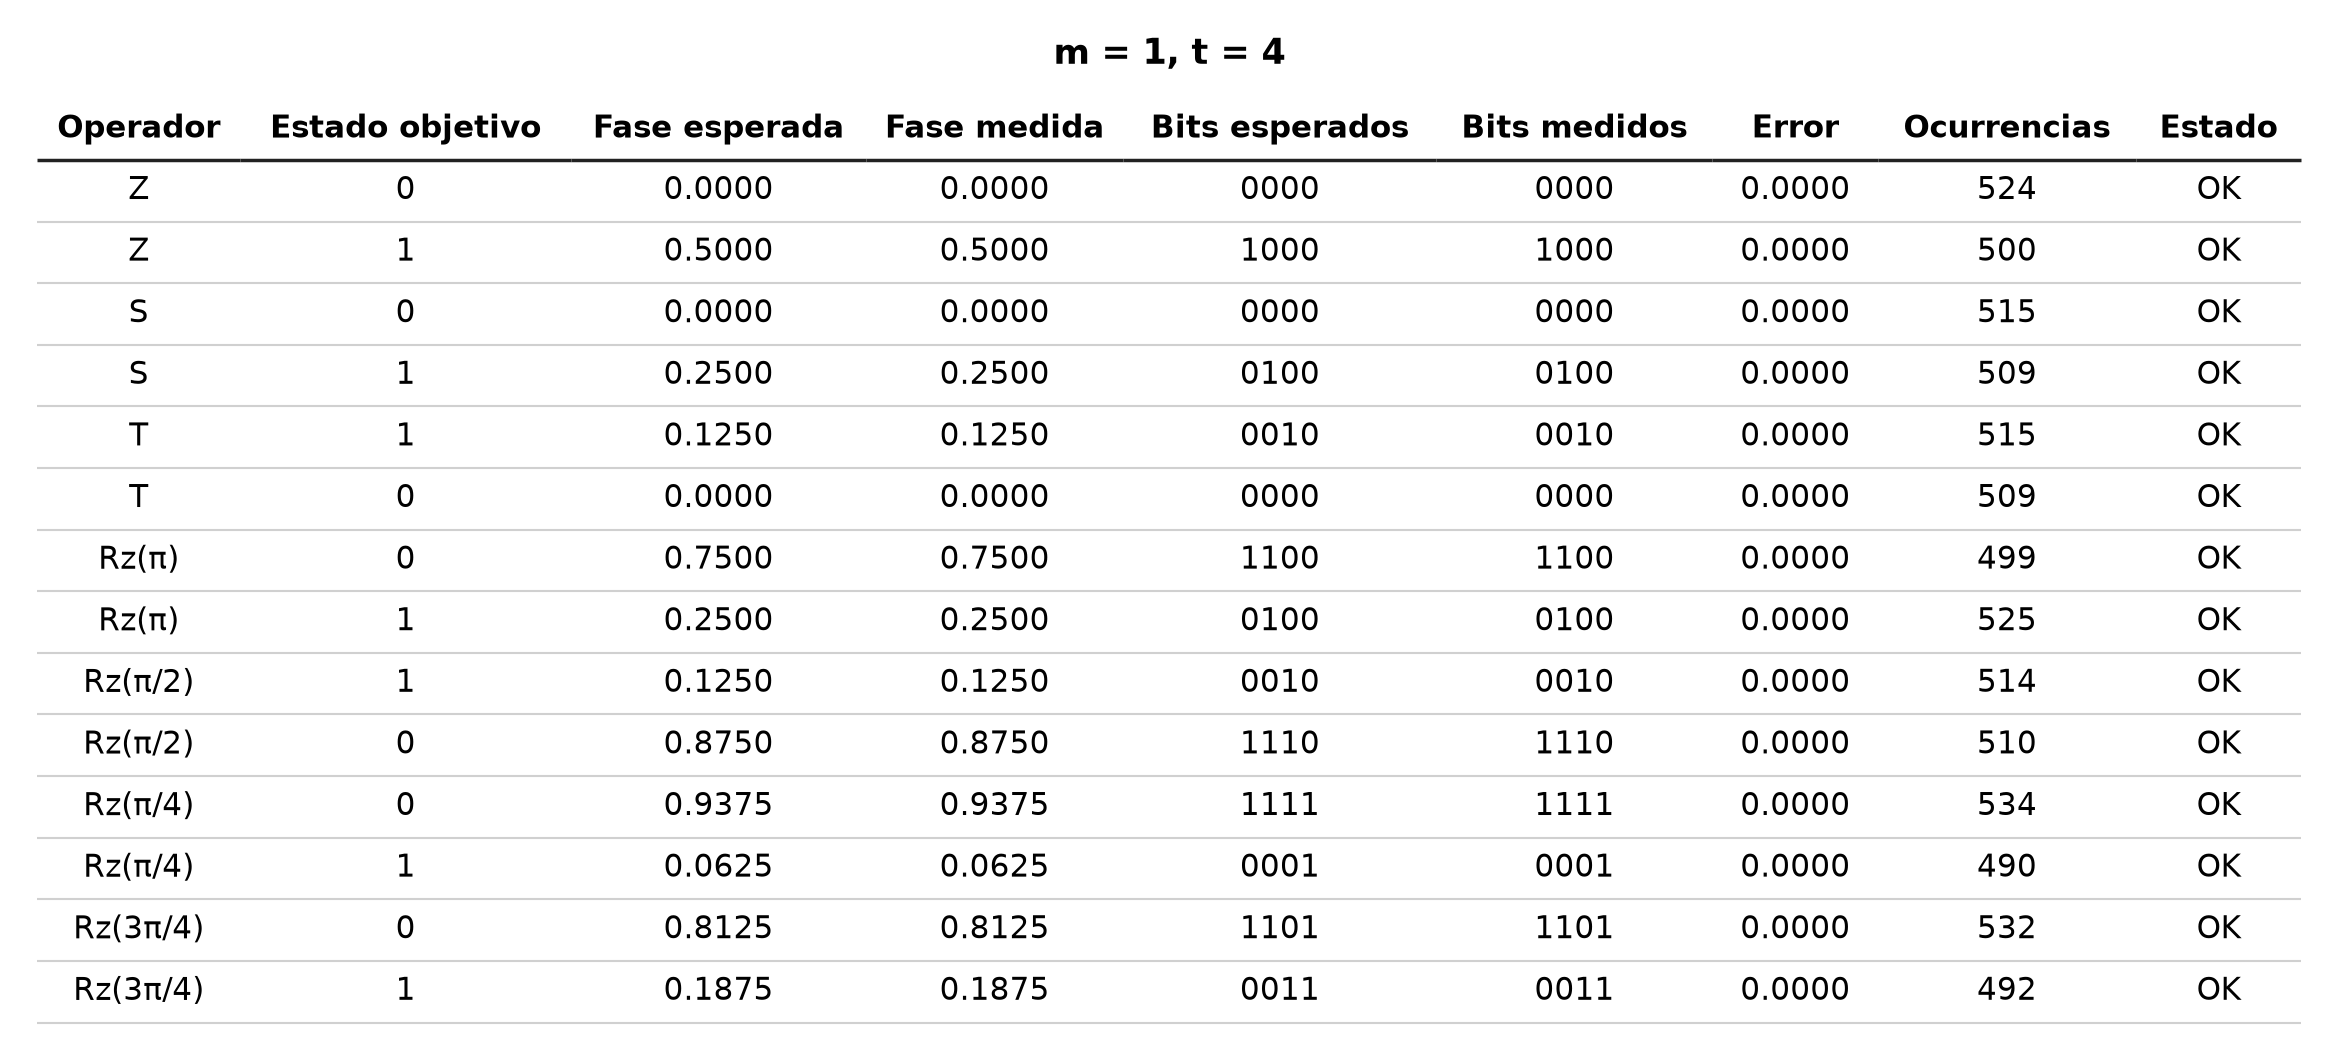

In [23]:
# Se establecen los parámetros.
m = 1
t = 4

# Se evalúa el circuito.
show_table(evaluate_qpe(m, t), title=f"m = {m}, t = {t}")

#### Inciso ii)

Mismas instrucciones que para el inciso i), pero utilizando $m = 2$ en lugar de $m = 1$.

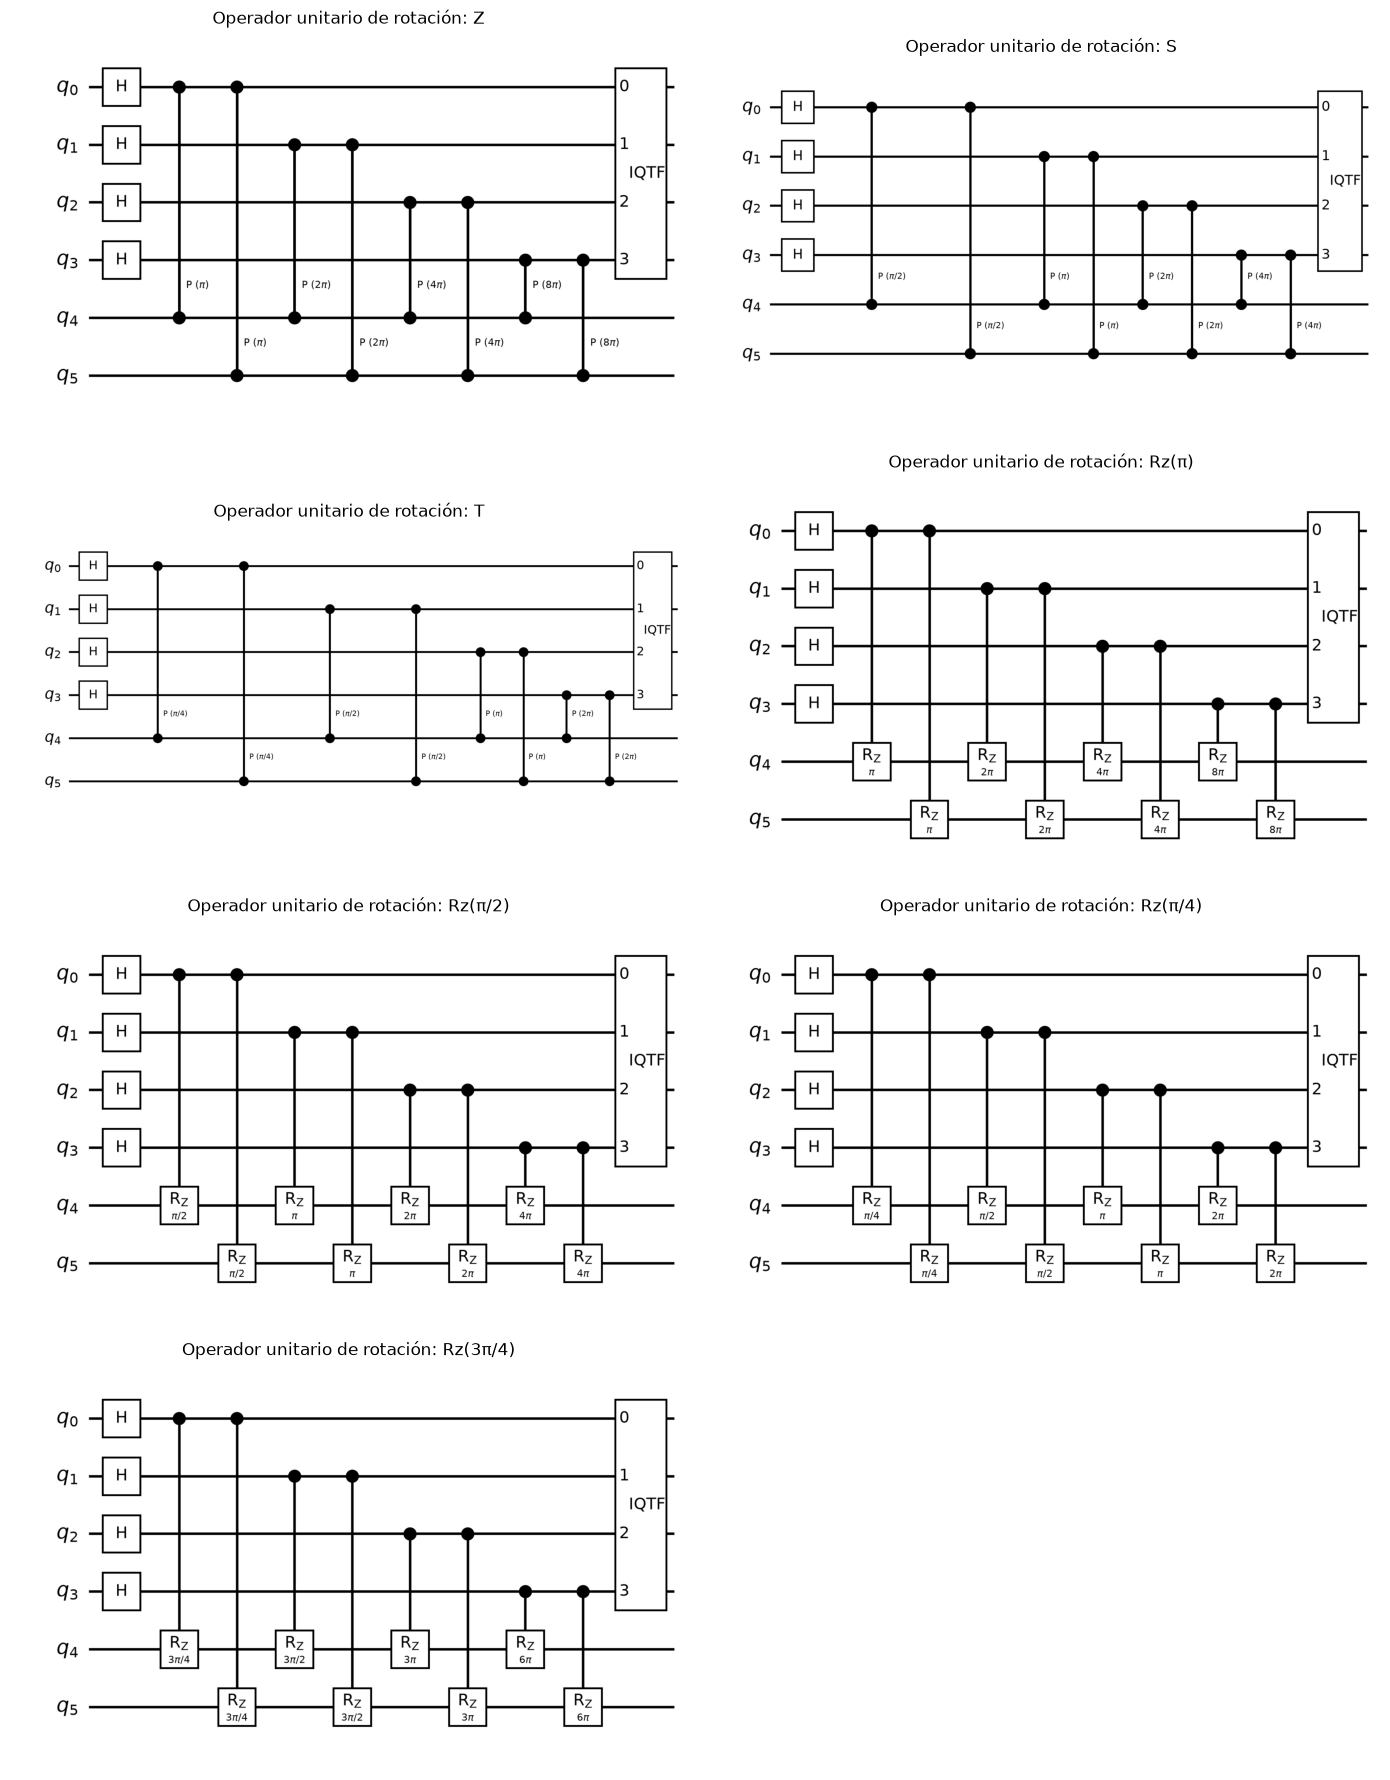

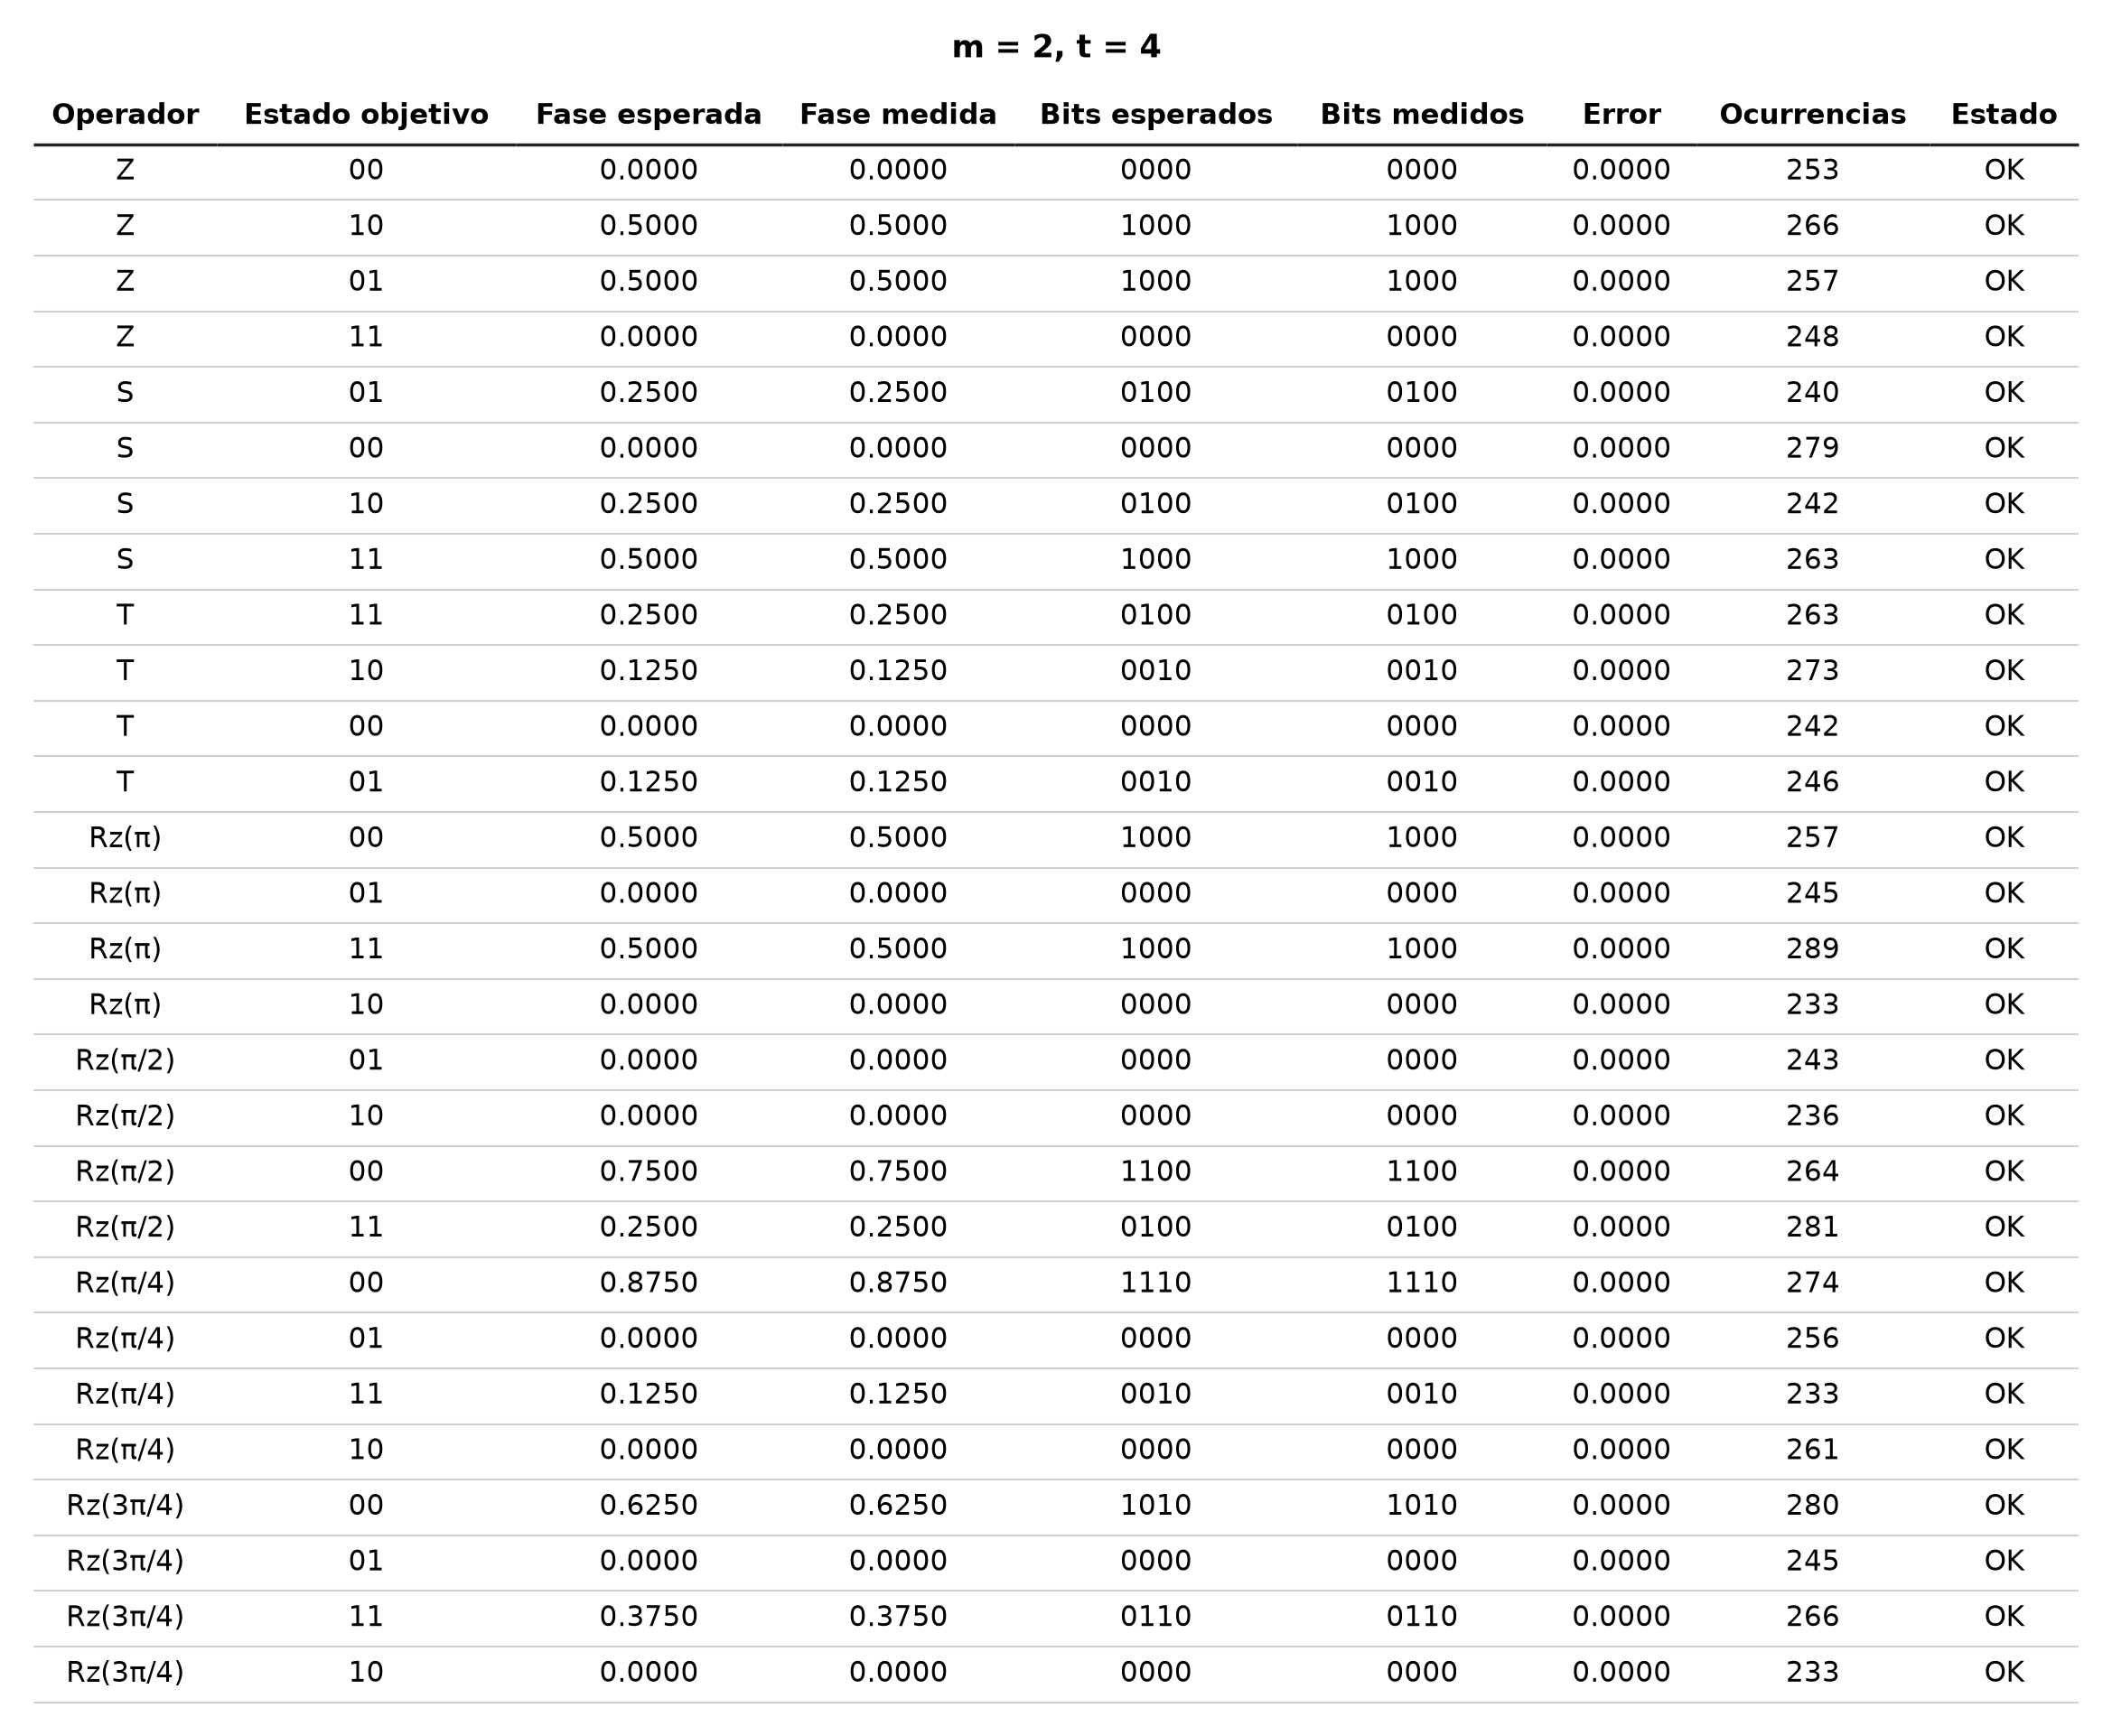

In [24]:
# Se establecen los parámetros.
m = 2
t = 4

# Se muestran los circuitos resultantes.
plot_circuits_grid(unitary_rotation_operators, m, t, columns=2)

# Se evalúa el circuito.
show_table(evaluate_qpe(m, t), title=f"m = {m}, t = {t}")

#### Inciso iii)

Mismas instrucciones que para el inciso i), pero modificando el valor de $t$ de $t = 4$ a $t = 6$.

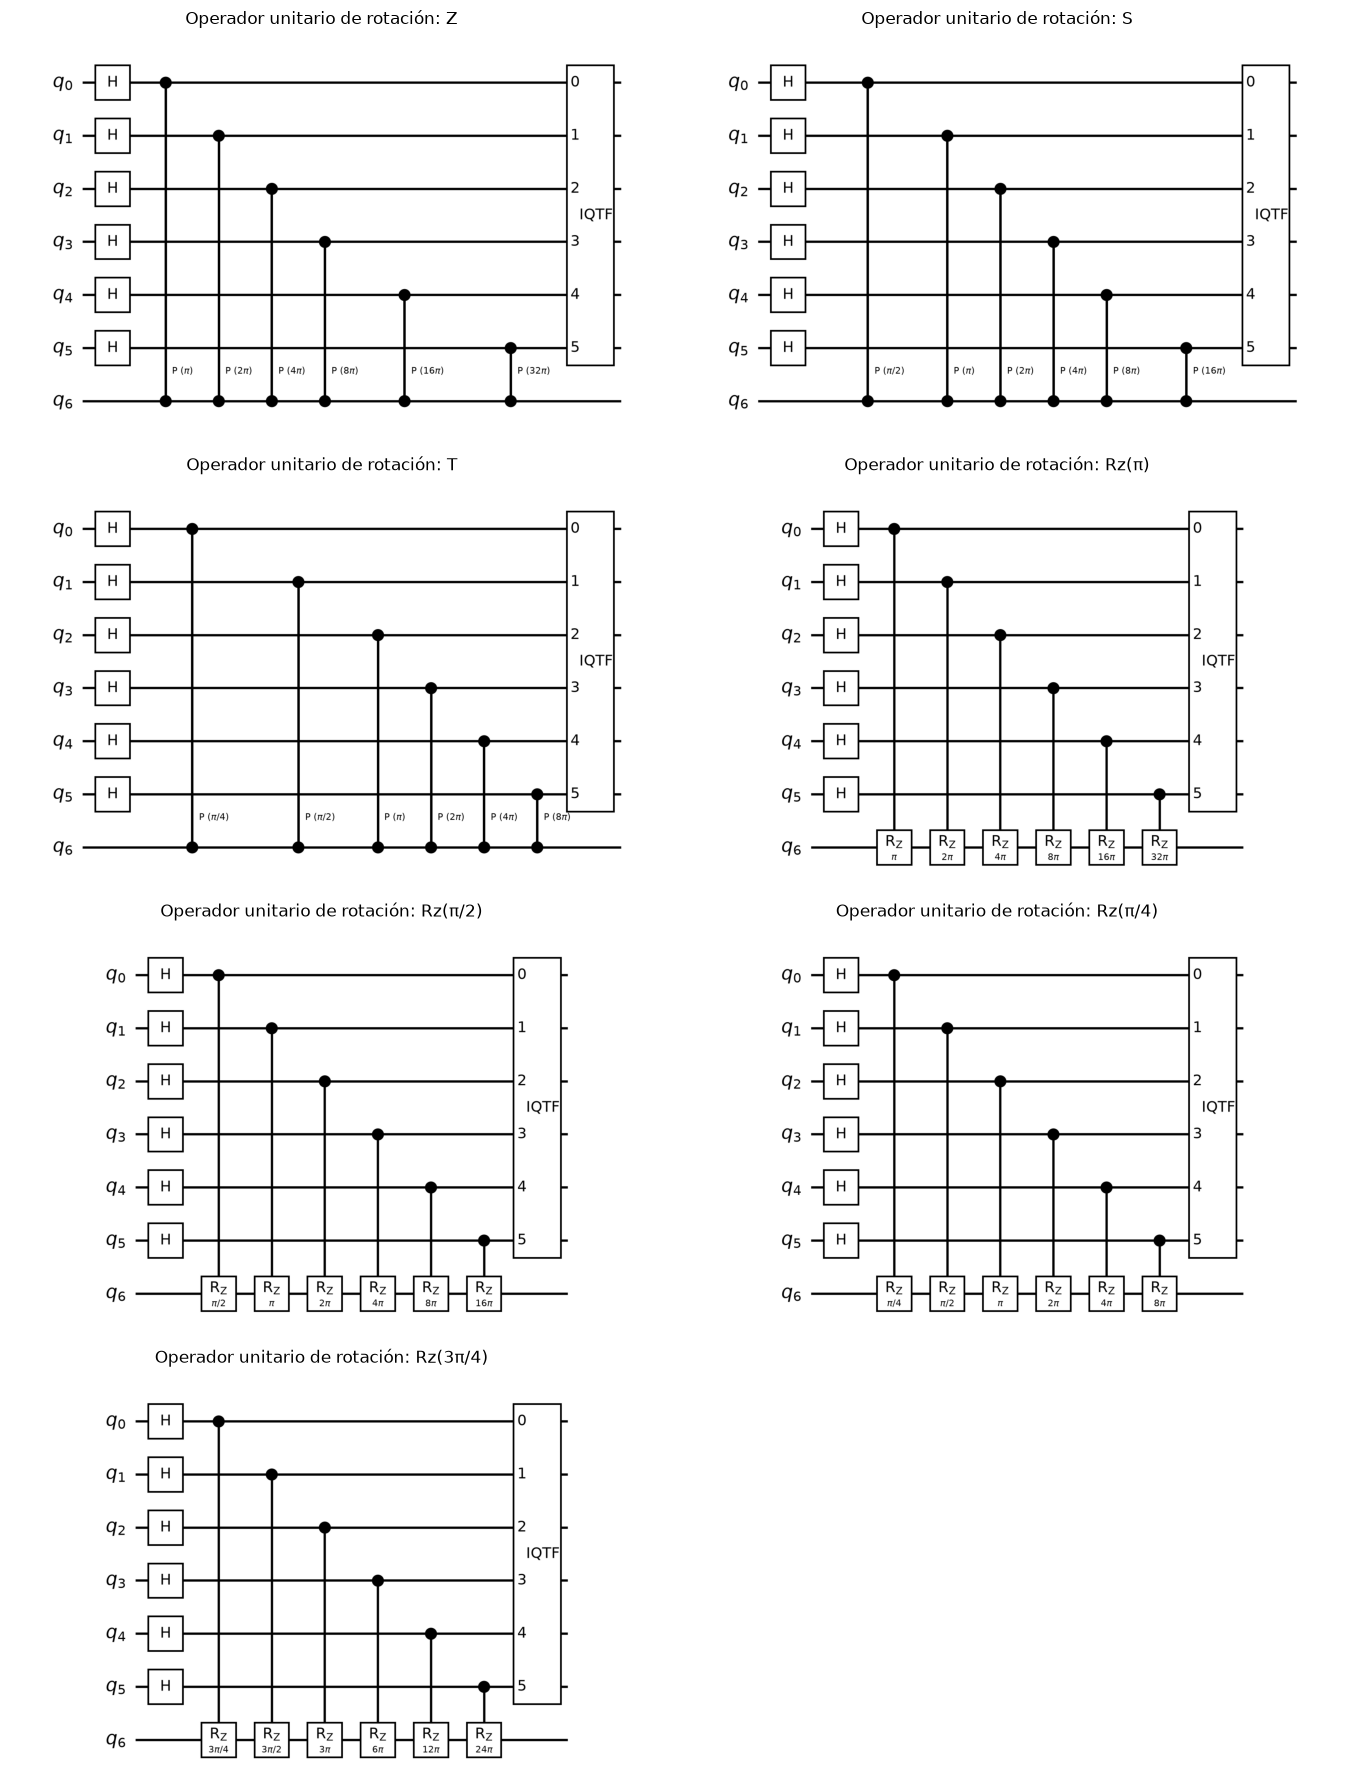

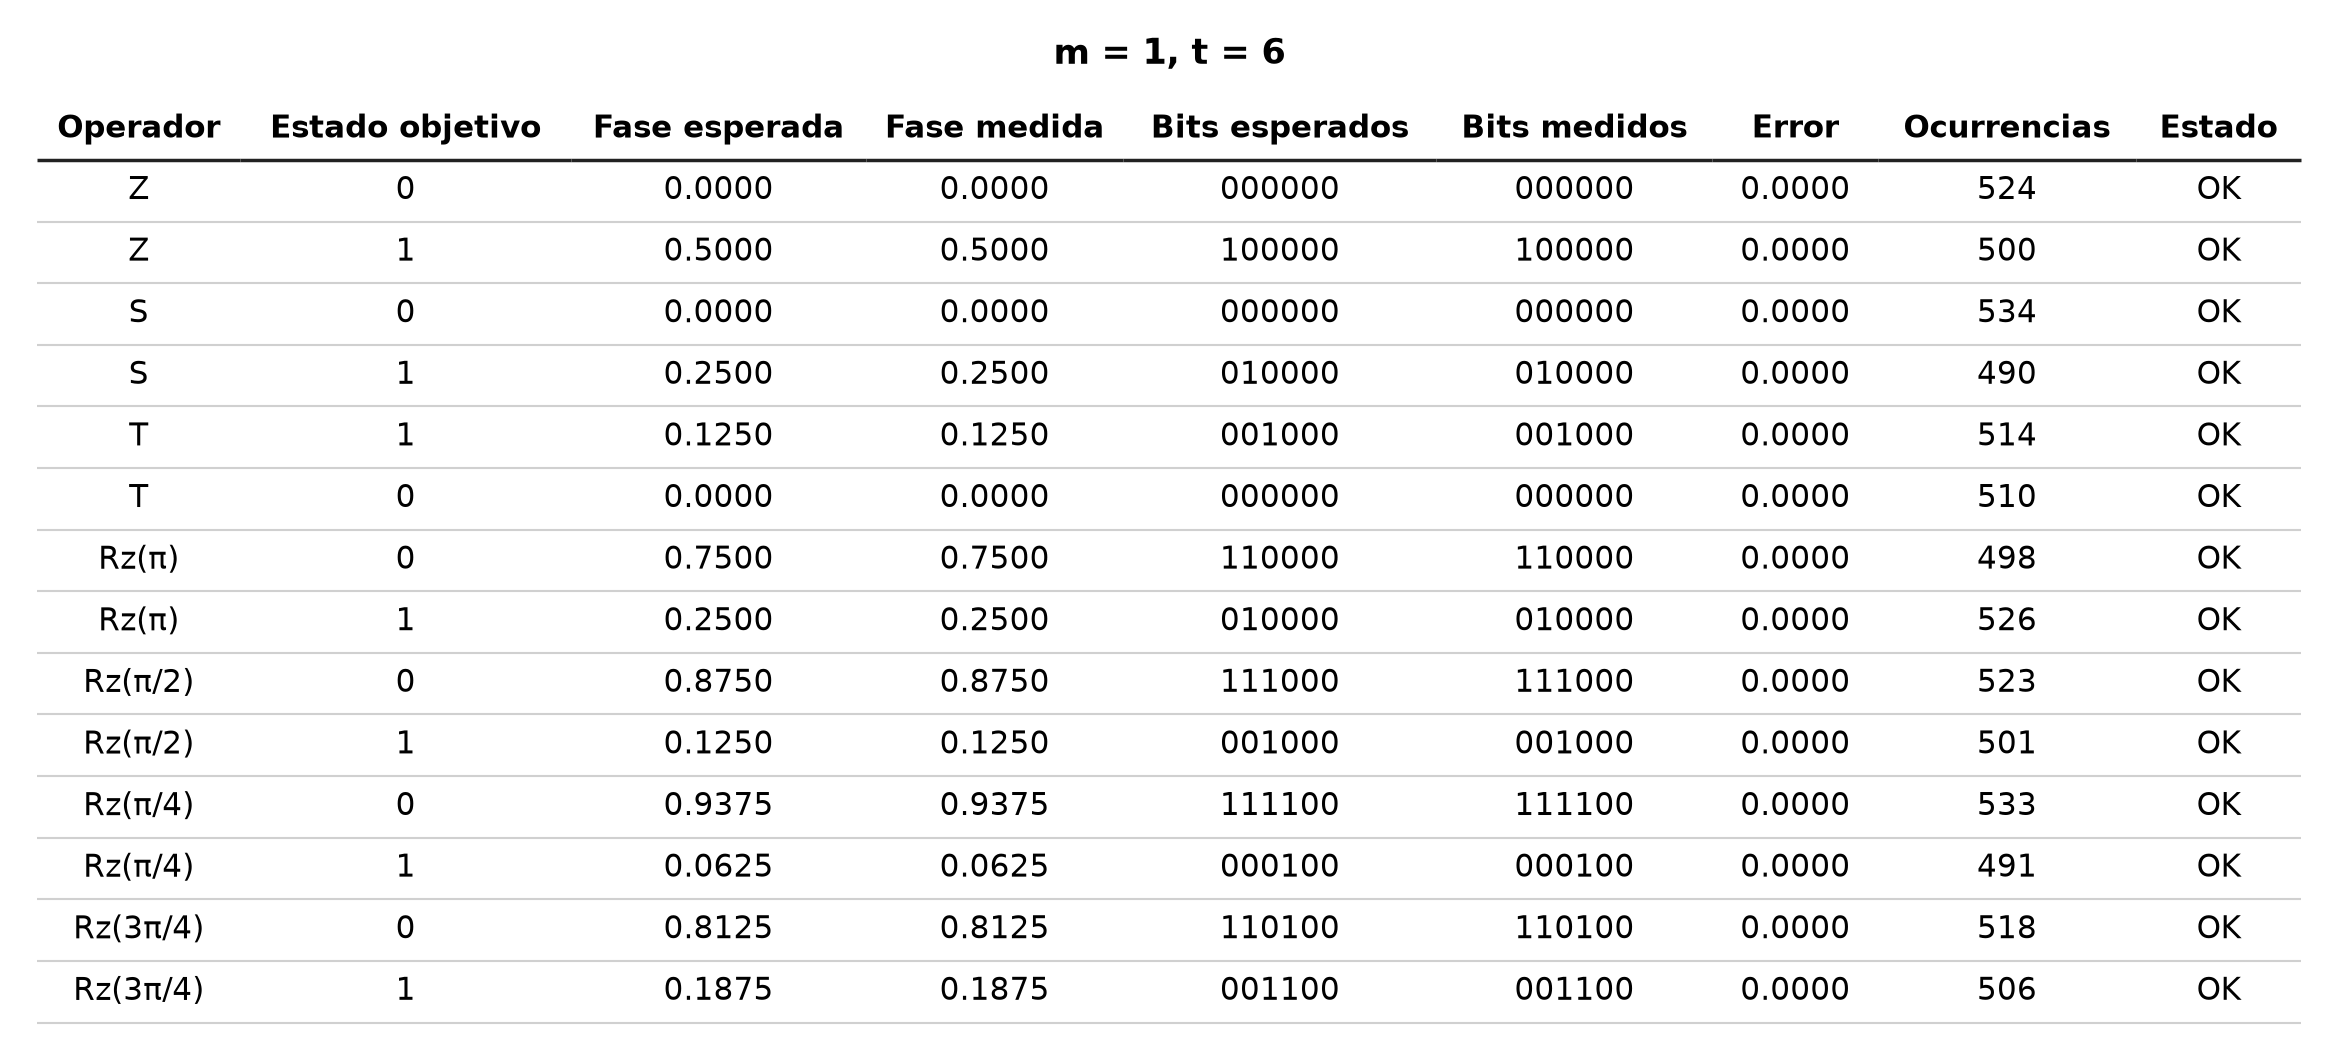

In [25]:
# Se establecen los parámetros.
m = 1
t = 6

# Se muestran los circuitos resultantes.
plot_circuits_grid(unitary_rotation_operators, m, t, columns=2)

# Se evalúa el circuito.
show_table(evaluate_qpe(m, t), title=f"m = {m}, t = {t}")

No se observa ninguna modificación en los valores. Añadir 2 qubits más de estimación no mejoró la precisión del resultado. Como puede observarse en la tabla, los últimos dos qubits se encuentran en 0 en todos los resultados. No realizan ningún aporte.

#### Inciso iv)

El inciso pide, utilizando $m = 1$ y $t = 4$, probar la implementación para un nuevo conjunto de operadores unitarios:

- $U = Rz(-𝝅/4)$; y
- $U = Rz(-3𝝅/4)$.

A continuación, se muestra la implementación de dichos circuitos para $m = 1$ y $t = 4$.

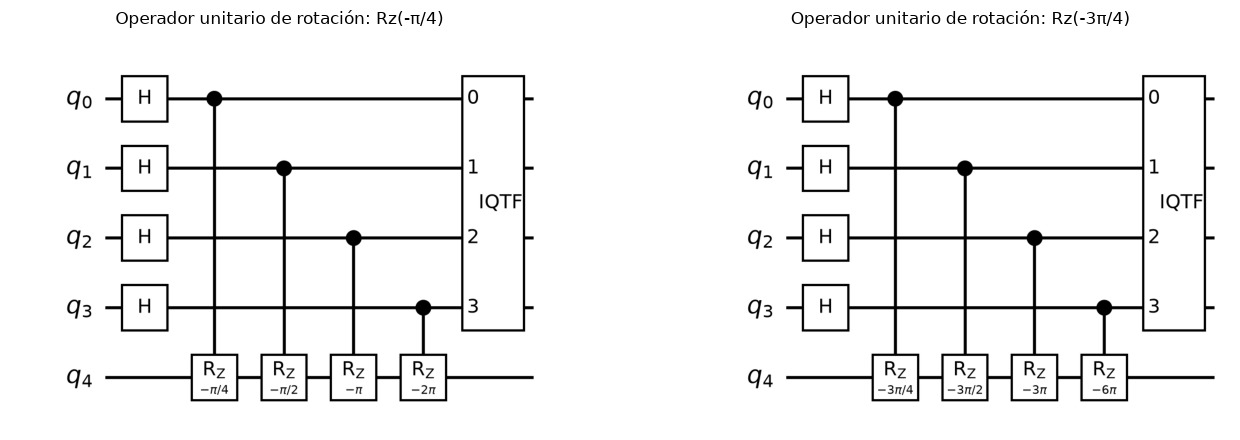

In [26]:
# Se establecen los valores de los parámetros.
m = 1
t = 4

# Se definen los nuevos operadores unitarios a utilizar.
unitary_rotation_operators_iv = ["Rz(-π/4)", "Rz(-3π/4)"]

# Se muestran los circuitos resultantes.
plot_circuits_grid(unitary_rotation_operators_iv, m, t, columns=2)

Con los circuitos presentados, se realiza su evaluación y se presentan los resultados mediante una tabla.

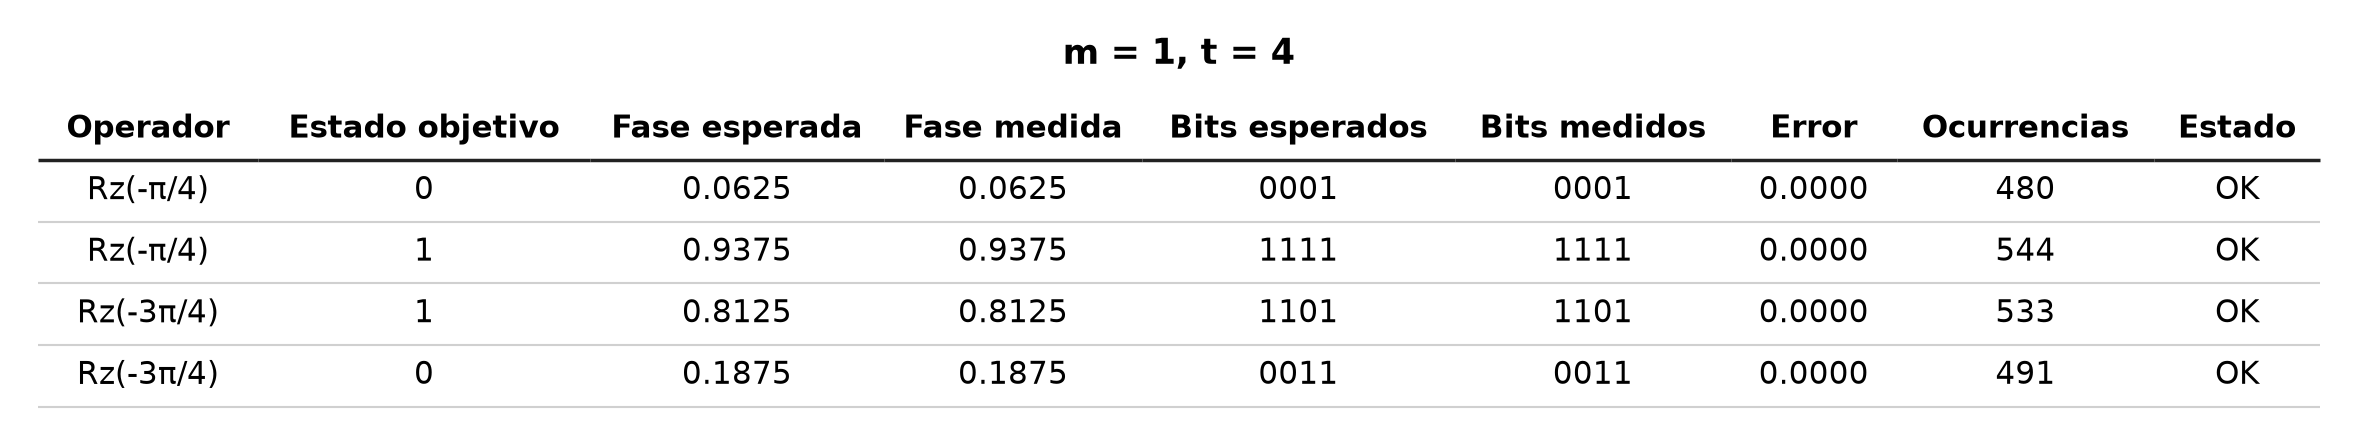

In [27]:
# Se evalúa el circuito.
show_table(evaluate_qpe(m, t, operators=unitary_rotation_operators_iv), title=f"m = {m}, t = {t}")

Como puede comprobarse, la implementación del circuito es correcta.

## Ejercicio 2

### Consigna

Analice para el ejercicio 1.i) el impacto de la fase global en los autovalores.

### Resolución

Para observar el impacto de la fase global en los autovalores, se evalúa el circuito con los operadores unitarios de rotación $Z$ y $Rz(\pi)$.

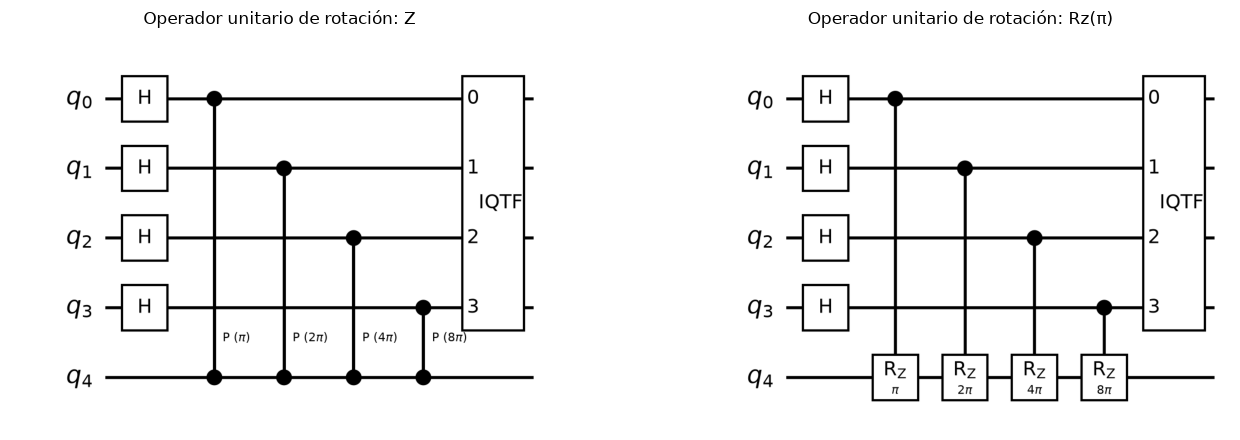

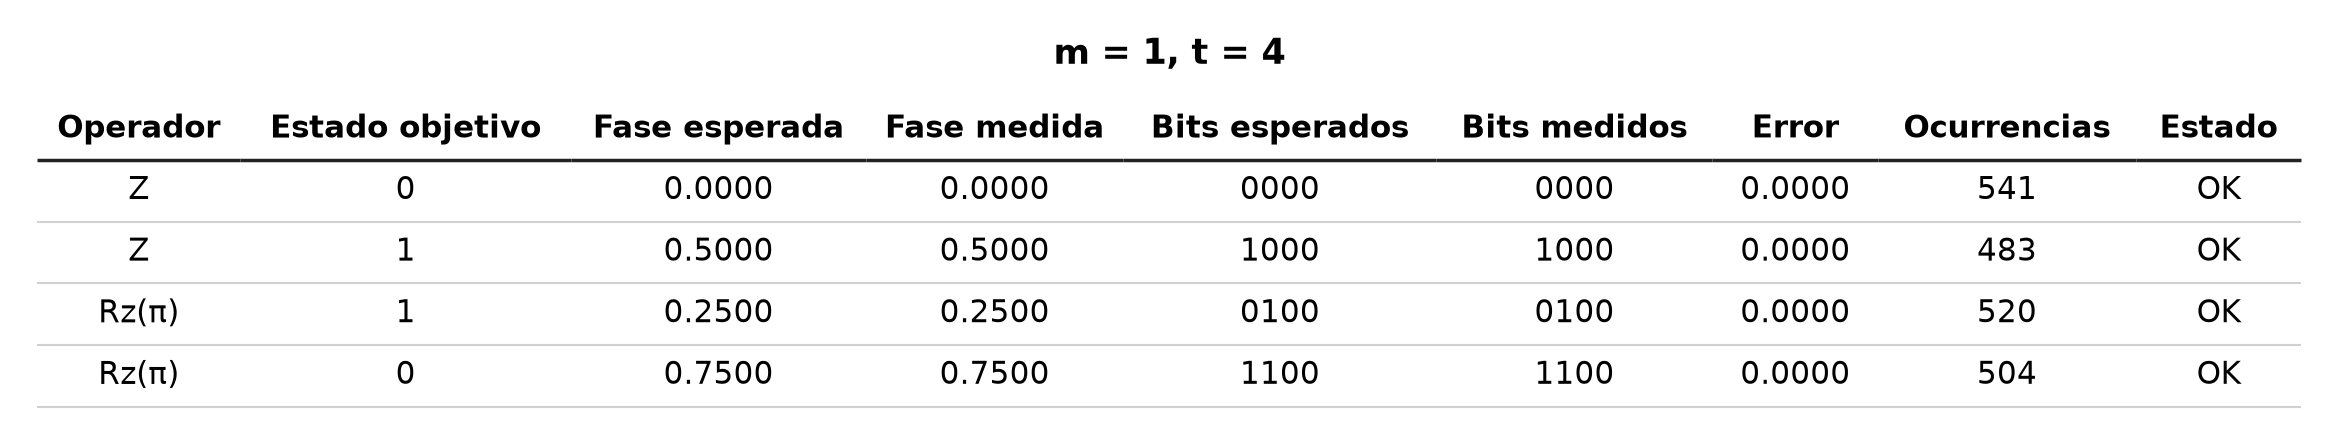

In [28]:
# Se establecen los valores de los parámetros.
m = 1
t = 4

# Se definen los nuevos operadores unitarios a utilizar.
unitary_rotation_operators_2 = ["Z", "Rz(π)"]

# Se muestran los circuitos resultantes.
plot_circuits_grid(unitary_rotation_operators_2, m, t, columns=2)

# Se evalúa el circuito.
show_table(evaluate_qpe(m, t, operators=unitary_rotation_operators_2), title=f"m = {m}, t = {t}")

Ambos operadores realizan una rotación $\pi$ sobre el eje Z. No obstante, $Rz(\pi)$ difiere de $Z$ en una fase global:

$$
Rz(\pi) = \begin{pmatrix} e^{-i\pi/2} & 0 \\ 0 & e^{i\pi/2} \end{pmatrix} = \begin{pmatrix} -i & 0 \\ 0 & i \end{pmatrix} = -i\,Z
$$

Si estas compuertas se aplicaran a un qubit y se realizara la medición, las probabilidades observadas serían las mismas para cualquier estado, ya que una fase global no es observable. Sin embargo, como se observa en la tabla anterior, esto no se cumple en el circuito QPE.

Los autovalores de $Z$ son $1$ y $-1$, mientras que los de $Rz(\pi)$ son $-i$ y $i$. Es decir, la fase global $e^{-i\pi/2}$ multiplica ambos autovalores, lo que desplaza las dos fases estimadas en $-0.25$ (módulo 1). La diferencia entre las fases de $\lvert 0 \rangle$ y $\lvert 1 \rangle$ se mantiene en $0.5$.

Esto ocurre porque el QPE utiliza el operador controlado. Cuando el qubit de control está en $\lvert 1 \rangle$, se aplica $U$ al objetivo, y cuando está en $\lvert 0 \rangle$, no se aplica nada. Por lo tanto, la fase global de $U$ deja de ser global y pasa a ser una fase relativa entre $\lvert 0 \rangle$ y $\lvert 1 \rangle$ del qubit de control (_phase kickback_), que es justamente lo que el QPE estima.

En conclusión, la fase global no afecta las probabilidades de medición de un estado, pero sí la fase estimada por el QPE, por lo que el operador debe especificarse con su fase global incluida.